In [1]:
import numpy as np
import seaborn as sns
import os
import matplotlib.pyplot as plt
from pathlib import Path

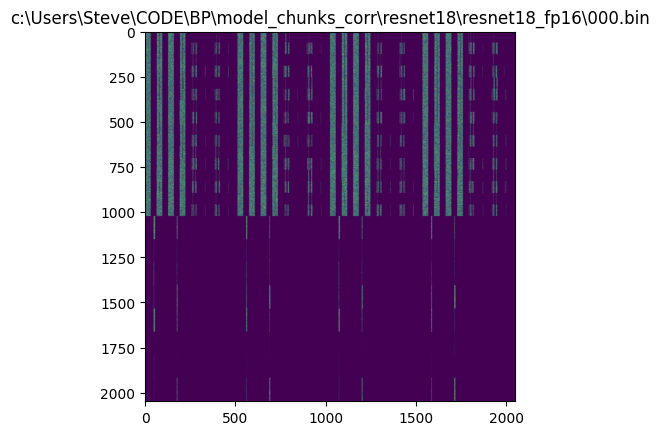

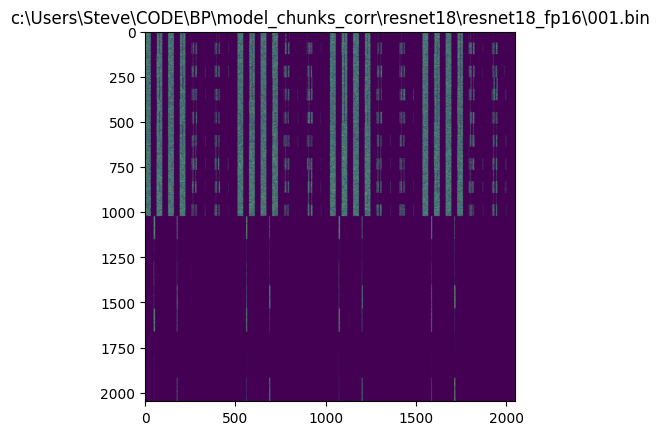

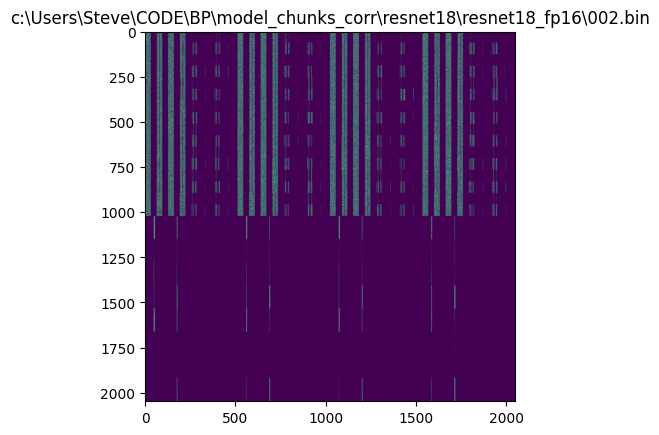

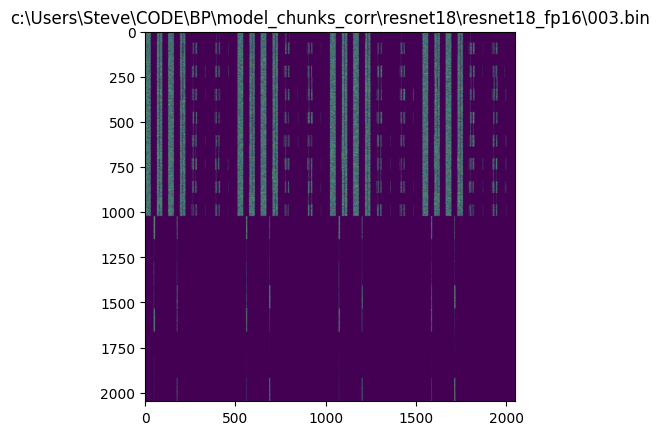

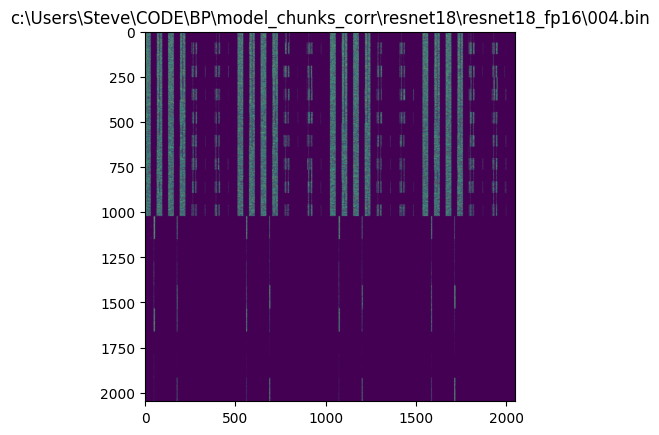

...

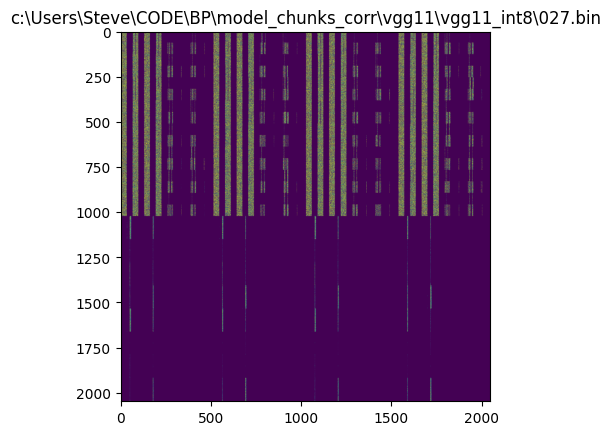

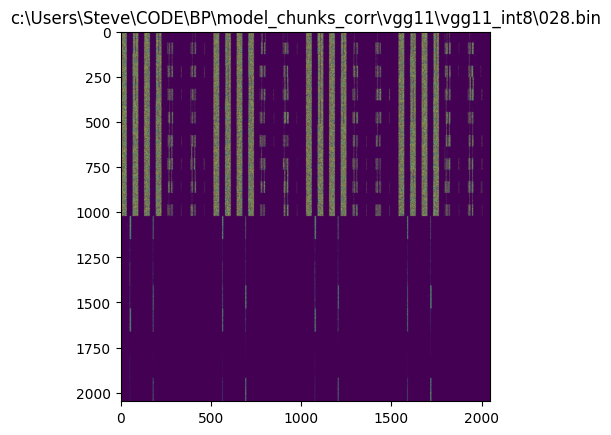

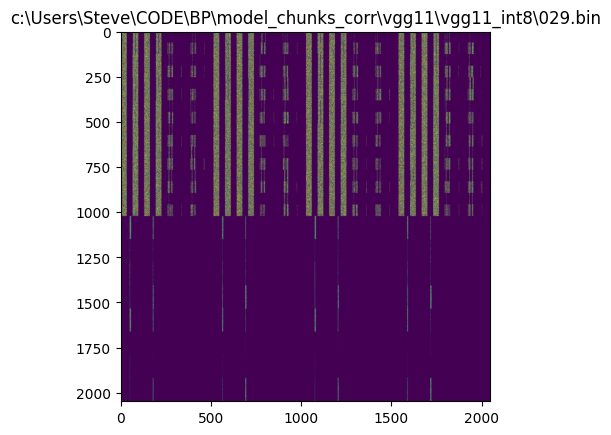

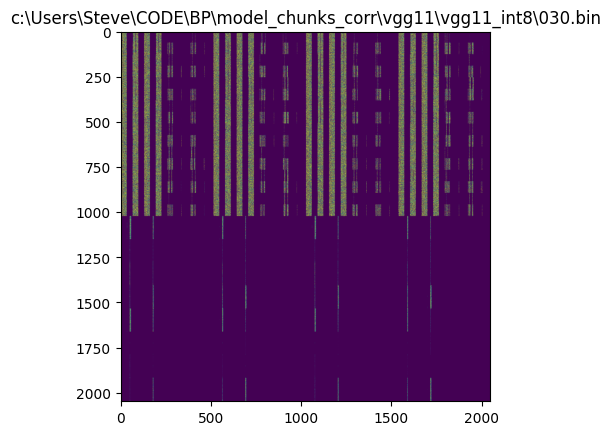

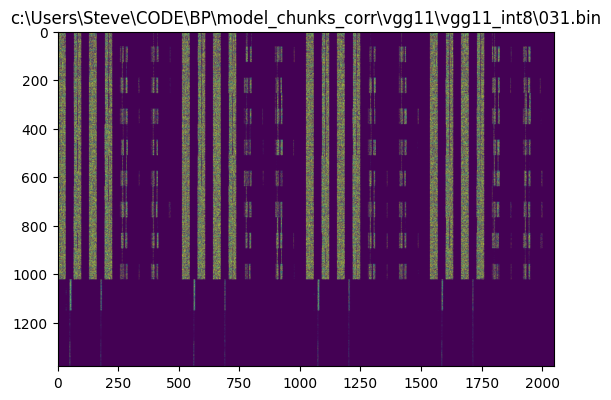

resnet18_resnet18_fp16_000 , 0.14446687698364258
resnet18_resnet18_fp16_001 , 0.14554429054260254
resnet18_resnet18_fp16_002 , 0.13807940483093262
resnet18_resnet18_fp16_003 , 0.1376967430114746
resnet18_resnet18_fp16_004 , 0.14586520195007324
resnet18_resnet18_fp16_005 , 0.25075304739044146
resnet18_resnet18_fp32_000 , 0.14264416694641113
resnet18_resnet18_fp32_001 , 0.13476896286010742
resnet18_resnet18_fp32_002 , 0.1375560760498047
resnet18_resnet18_fp32_003 , 0.1407175064086914
resnet18_resnet18_fp32_004 , 0.14058494567871094
resnet18_resnet18_fp32_005 , 0.13536763191223145
resnet18_resnet18_fp32_006 , 0.13277626037597656
resnet18_resnet18_fp32_007 , 0.14270567893981934
resnet18_resnet18_fp32_008 , 0.13857555389404297
resnet18_resnet18_fp32_009 , 0.13811969757080078
resnet18_resnet18_fp32_010 , 0.13429617881774902
resnet18_resnet18_fp32_011 , 0.17030316235059761
resnet18_resnet18_int4_000 , 0.08478283882141113
resnet18_resnet18_int4_001 , 0.17210263854039018
resnet18_resnet18_int8_

In [2]:
org = Path.cwd() / "model_chunks_corr"

all = {}

for i in sorted(org.rglob("*.bin")):
    orig = (
        Path.cwd() / "model_chunks" / i.parent.parent.stem / i.parent.stem / i.name
    ).read_bytes()
    corr = i.read_bytes()

    key = i.parent.parent.stem + "_" + i.parent.stem + "_" + i.stem
    
    orig = np.frombuffer(orig, dtype=np.uint8)
    corr = np.frombuffer(corr, dtype=np.uint8)
    
    plt.title(str(i))
    xored = np.bitwise_xor(orig, corr)
    xored = np.pad(xored, (0, (-xored.size)%2**11), mode="constant")
        
    plt.imshow(xored.reshape((-1, 2**11)))
    plt.show()

    corr = np.count_nonzero(
        np.bitwise_xor(
            np.frombuffer(orig, dtype=np.uint8),
            np.frombuffer(corr, dtype=np.uint8),
        )
    )

    if key in all:
        all[key] += corr
        all[key + "_num"] += len(orig)
    else:
        all[key] = corr
        all[key + "_num"] = len(orig)

# print(all)

for i in all:
    if i.endswith("_num"):
        i = i[:-4]
        print(i, ",", all[i] / all[i + "_num"])